In [ ]:
!pip install numpy  cv2 -q

ERROR: Could not find a version that satisfies the requirement cv2 (from versions: none)
ERROR: No matching distribution found for cv2


# Prespective Transform

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import easyocr
import pytesseract
from pytesseract import Output
import os


In [ ]:
aspect_ratio=1.585

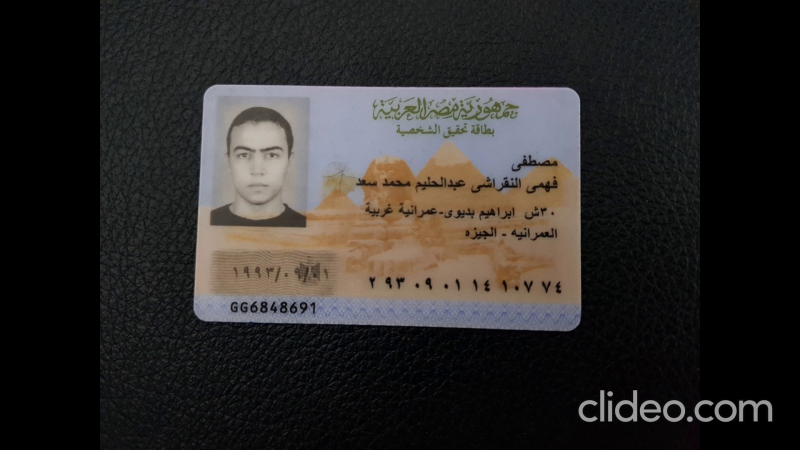

In [ ]:
def read_image(image_path: str):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Could not load image at path: {image_path}")
    return img


img = read_image("/content/file95.png")
cv2_imshow(img)

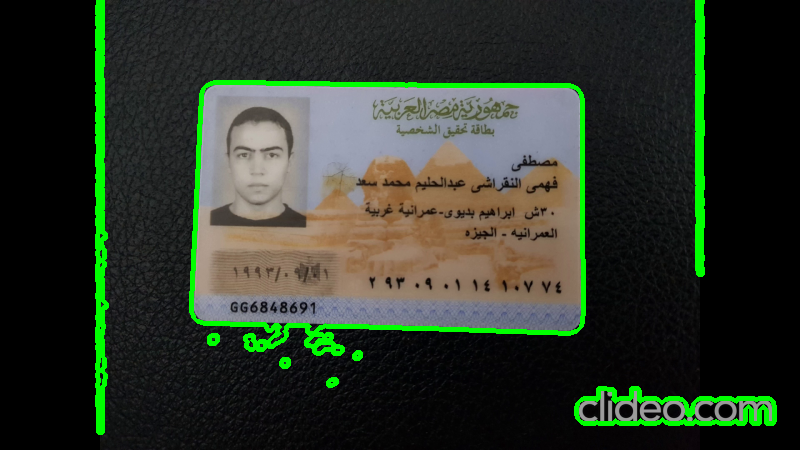

In [ ]:
import cv2
import numpy as np

def extract_contours(image, apply_clahe=False):
    """Extracts edges, with an optional CLAHE toggle for tricky lighting."""
    img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Conditionally apply CLAHE
    if apply_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_gray = clahe.apply(img_gray)

    img_smoothed = cv2.bilateralFilter(img_gray, 11, 17, 17)
    edges = cv2.Canny(img_smoothed, 30, 70)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
    edges_dilated = cv2.dilate(edges_closed, kernel, iterations=1)

    contours, _ = cv2.findContours(edges_dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return sorted(contours, key=cv2.contourArea, reverse=True)[:10]

img_copy=img.copy()
contours=extract_contours(img_copy)
cv2.drawContours(img_copy,contours , -1, (0, 255, 0), 3)
cv2_imshow(img_copy)




In [ ]:
def extract_corner_points(biggest_contour):
    points = biggest_contour.reshape((4, 2))
    input_points = np.zeros((4, 2), dtype="float32")

    points_sum = points.sum(axis=1)
    input_points[0] = points[np.argmin(points_sum)]  # Top-Left
    input_points[3] = points[np.argmax(points_sum)]  # Bottom-Right

    points_diff = np.diff(points, axis=1)
    input_points[1] = points[np.argmin(points_diff)] # Top-Right
    input_points[2] = points[np.argmax(points_diff)] # Bottom-Left

    # Correct unpacking order
    return input_points[0], input_points[1], input_points[3], input_points[2]




In [ ]:
def get_valid_card_box(image, contours):
    """Analyzes contours and returns corners ONLY if a valid ID shape is found."""
    image_area = image.shape[0] * image.shape[1]
    best_box = None
    max_area = 0

    for i in contours:
        rect = cv2.minAreaRect(i)
        box = cv2.boxPoints(rect)
        box = np.float32(box)

        width, height = rect[1][0], rect[1][1]
        if width == 0 or height == 0:
            continue

        box_area = width * height
        ratio = max(width, height) / min(width, height)

        # Validation checks
        if (image_area * 0.05) < box_area < (image_area * 0.95):
            if 1.2 < ratio < 2.0:
                if box_area > max_area:
                    best_box = box
                    max_area = box_area

    if best_box is not None:
        return extract_corner_points(best_box)

    return None # Explicitly return None if no valid shape is found

In [ ]:
def get_smart_corners(image):
    """Master function that manages the Double-Pass and Plan B logic."""

    # 1. PASS 1: Try without CLAHE (Best for black tables / high contrast)
    contours_standard = extract_contours(image, apply_clahe=False)
    corners = get_valid_card_box(image, contours_standard)

    if corners is not None:
        print("Plan A (Pass 1): Standard contrast detection successful.")
        return corners

    # 2. PASS 2: Try WITH CLAHE (Best for white sheets / low contrast)
    print("Pass 1 failed. Attempting Pass 2 with CLAHE...")
    contours_clahe = extract_contours(image, apply_clahe=True)
    corners = get_valid_card_box(image, contours_clahe)

    if corners is not None:
        print("Plan A (Pass 2): CLAHE contrast detection successful.")
        return corners

    # 3. PLAN B: Fallback to fixed corners if math fails entirely
    print("Plan B: All contour detection failed. Using fixed image corners.")
    h, w = image.shape[:2]
    top_left = [0, 0]
    top_right = [w - 1, 0]
    bottom_right = [w - 1, h - 1]
    bottom_left = [0, h - 1]

    return top_left, top_right, bottom_right, bottom_left

Plan A (Pass 1): Standard contrast detection successful.


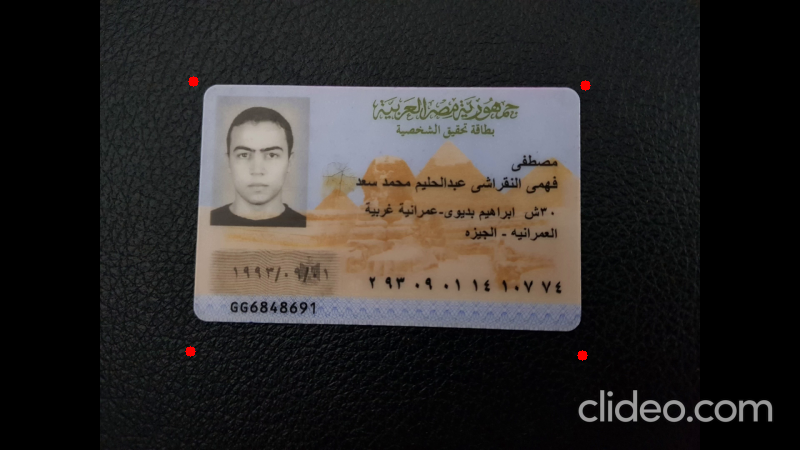

In [ ]:
img_copy = img.copy()
top_left, top_right, bottom_right, bottom_left=get_smart_corners(img_copy)
cv2.circle(img_copy, (int(top_left[0]),int(top_left[1])), 5, (0, 0, 255), -1)
cv2.circle(img_copy, (int(top_right[0]),int(top_right[1])), 5, (0, 0, 255), -1)
cv2.circle(img_copy, (int(bottom_right[0]),int(bottom_right[1])), 5, (0, 0, 255), -1)
cv2.circle(img_copy, (int(bottom_left[0]),int(bottom_left[1])), 5, (0, 0, 255), -1)
cv2_imshow(img_copy)


In [ ]:
def extract_dimensions(top_left, top_right, bottom_right, bottom_left, aspect_ratio):
    # np.linalg.norm calculates the Euclidean distance exactly like your sqrt formula, but cleaner
    bottom_width = np.linalg.norm(bottom_right - bottom_left)
    top_width = np.linalg.norm(top_right - top_left)

    max_width = max(int(bottom_width), int(top_width))

    # Standard ID cards are wider than they are tall (Landscape)
    # Using the physical aspect ratio enforces perfect rectangular deskewing
    max_height = int(max_width / aspect_ratio)

    return max_width, max_height

In [ ]:
def perspective_transform(image, aspect_ratio=1.586):
    # 1. Resize for faster, more reliable contour detection
    resize_ratio = 500.0 / image.shape[0]
    small_img = cv2.resize(image, (int(image.shape[1] * resize_ratio), 500))

    # 2. Get smart corners using the Double-Pass master function
    points = get_smart_corners(small_img)
    points = np.float32(points)

    # 3. Scale coordinates back up to original high-res image
    points = points / resize_ratio
    top_left, top_right, bottom_right, bottom_left = points

    # 4. Extract target dimensions
    max_width, max_height = extract_dimensions(top_left, top_right, bottom_right, bottom_left, aspect_ratio)

    input_points = np.float32([top_left, top_right, bottom_right, bottom_left])

    # 5. Map to a flat rectangle
    converted_points = np.float32([
        [0, 0],
        [max_width - 1, 0],
        [max_width - 1, max_height - 1],
        [0, max_height - 1]
    ])

    matrix = cv2.getPerspectiveTransform(input_points, converted_points)
    img_output = cv2.warpPerspective(image, matrix, (max_width, max_height))

    # --- 6. FORCE LANDSCAPE ORIENTATION ---
    # Standard ID cards are wider than they are tall.
    # If the output height is greater than the width, rotate it 90 degrees.
    h_out, w_out = img_output.shape[:2]
    if h_out > w_out:
        print("Detected vertical layout. Rotating to landscape...")
        img_output = cv2.rotate(img_output, cv2.ROTATE_90_CLOCKWISE)

        # Note: If the text ends up upside down after rotating clockwise,
        # swap to cv2.ROTATE_90_COUNTERCLOCKWISE

    img_output=cv2.resize(img_output,(750,600))
    # cv2_imshow(img_output)
    return img_output

Plan A (Pass 1): Standard contrast detection successful.


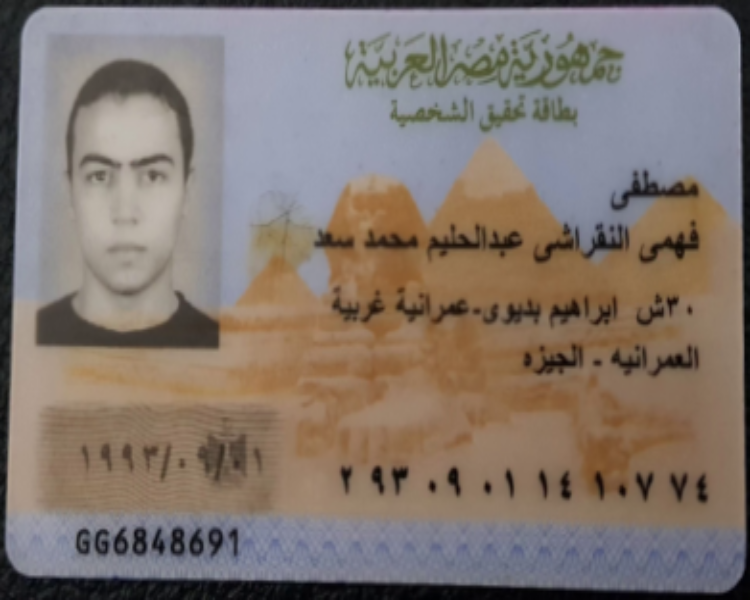

In [ ]:
img = read_image("/content/file95.png")
img_output=perspective_transform(img)

cv2_imshow(img_output)

# Field Extraction

Plan A (Pass 1): Standard contrast detection successful.


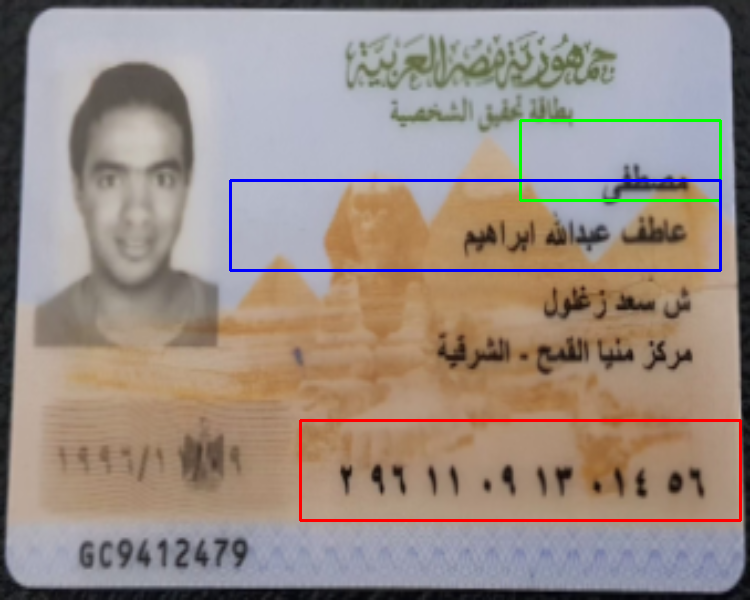

In [ ]:
img = read_image("/content/file48.png")
img_output=perspective_transform(img)

xl_name,yl_name,xr_name,yr_name=520,120,720,200
xl_full,yl_full,xr_full,yr_full=230,180,720,270
xl_id,yl_id,xr_id,yr_id=300,420,740,520



cv2.rectangle(img_output, (xl_name, yl_name), (xr_name, yr_name), (0, 255, 0), 2)
cv2.rectangle(img_output, (xl_full, yl_full), (xr_full, yr_full), (255, 0, 0), 2)
cv2.rectangle(img_output, (xl_id, yl_id), (xr_id, yr_id), (0, 0, 255), 2)

cv2_imshow(img_output)

In [ ]:
def crop_first_name(img, xl=520, yl=120, xr=720, yr=210):
    """Crops a specific region of interest (like a first name field) from an image."""
    # Ensure coordinates are integers for pixel indexing
    x1, y1 = int(xl), int(yl)
    x2, y2 = int(xr), int(yr)

    # Slice the numpy array image [ymin:ymax, xmin:xmax]
    cropped_img = img[y1:y2, x1:x2]
    # cropped_img=cv2.cvtColor(cropped_img,cv2.COLOR_BGR2GRAY)
    return cropped_img

In [ ]:
def crop_full_name(img, xl=230, yl=190, xr=720, yr=270):
    """Crops a specific region of interest (like a first name field) from an image."""
    # Ensure coordinates are integers for pixel indexing
    x1, y1 = int(xl), int(yl)
    x2, y2 = int(xr), int(yr)

    # Slice the numpy array image [ymin:ymax, xmin:xmax]
    cropped_img = img[y1:y2, x1:x2]
    # cropped_img=cv2.cvtColor(cropped_img,cv2.COLOR_BGR2GRAY)
    return cropped_img

In [ ]:
def crop_id(img, xl=300, yl=420, xr=740, yr=540):
    """Crops a specific region of interest (like a first name field) from an image."""
    # Ensure coordinates are integers for pixel indexing
    x1, y1 = int(xl), int(yl)
    x2, y2 = int(xr), int(yr)

    # Slice the numpy array image [ymin:ymax, xmin:xmax]
    cropped_img = img[y1:y2, x1:x2]
    # cropped_img=cv2.cvtColor(cropped_img,cv2.COLOR_BGR2GRAY)
    return cropped_img

Plan A (Pass 1): Standard contrast detection successful.
(600, 750, 3)


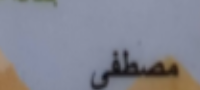

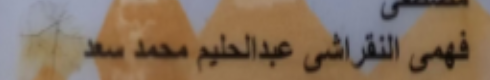

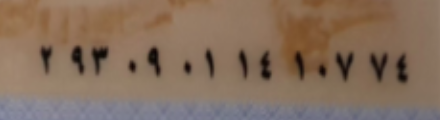

In [ ]:
img = read_image("/content/file95.png")
img_output=perspective_transform(img)
print(img_output.shape)
first_name_img=crop_first_name(img_output)
full_name_img=crop_full_name(img_output)
id_img=crop_id(img_output)


cv2_imshow(first_name_img)
print("="*50)
cv2_imshow(full_name_img)
print("="*50)
cv2_imshow(id_img)

# Paddle Ocr

In [ ]:
!pip install paddlepaddle paddleocr numpy opencv-python -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 984.1 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 75.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/

In [ ]:

import cv2
import numpy as np


def preprocess_field(image):
    """
    Simplified preprocessing for OCR field crops without Otsu,
    adaptive thresholding, morphological operations, or sharpening.

    Input:
        image: OpenCV BGR image

    Output:
        processed: 3-channel BGR image
    """

    # 1. Ensure image is BGR
    if image is None:
        raise ValueError("Image is None")

    if len(image.shape) == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    original = image.copy()

    # 2. Grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 3. Simple fixed luminance threshold (replaces adaptive thresholding)
    # Assumes text is darker than ID background (pixel intensity < 120)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    _, mask = cv2.threshold(blurred, 120, 255, cv2.THRESH_BINARY_INV)

    # 4. Find text region using percentile bounds
    ys, xs = np.where(mask > 0)

    if len(xs) > 20:
        x_min = int(np.percentile(xs, 2))
        x_max = int(np.percentile(xs, 98))
        y_min = int(np.percentile(ys, 5))
        y_max = int(np.percentile(ys, 95))

        margin_x = max(5, int((x_max - x_min) * 0.5))
        margin_y = max(5, int((y_max - y_min) * 0.20))

        x_min = max(0, x_min - margin_x)
        x_max = min(gray.shape[1], x_max + margin_x)
        y_min = max(0, y_min - margin_y)
        y_max = min(gray.shape[0], y_max + margin_y)

        cropped = image[y_min:y_max, x_min:x_max]
    else:
        cropped = image.copy()

    # 5. Deskew using fixed threshold (replaces Otsu)
    gray_crop = cv2.cvtColor(cropped, cv2.COLOR_BGR2GRAY)
    _, deskew_mask = cv2.threshold(gray_crop, 120, 255, cv2.THRESH_BINARY_INV)

    coords = np.column_stack(np.where(deskew_mask > 0))

    if len(coords) > 20:
        rect = cv2.minAreaRect(coords[:, ::-1].astype(np.float32))
        angle = rect[-1]

        if angle < -45:
            angle = 90 + angle

        if abs(angle) < 10:
            h, w = cropped.shape[:2]
            center = (w // 2, h // 2)
            matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
            cropped = cv2.warpAffine(
                cropped,
                matrix,
                (w, h),
                flags=cv2.INTER_CUBIC,
                borderMode=cv2.BORDER_REPLICATE,
            )

    # 6. Estimate text height using basic intensity cutoff
    gray_crop = cv2.cvtColor(cropped, cv2.COLOR_BGR2GRAY)
    ys, _ = np.where(gray_crop < 120)

    if len(ys) > 20:
        y_min = int(np.percentile(ys, 5))
        y_max = int(np.percentile(ys, 95))
        text_height = y_max - y_min

        # 7. Resize to standard character height
        target_text_height = 64
        scale = target_text_height / max(text_height, 1)
        scale = np.clip(scale, 1.0, 4.0)

        new_w = int(cropped.shape[1] * scale)
        new_h = int(cropped.shape[0] * scale)

        cropped = cv2.resize(
            cropped, (new_w, new_h), interpolation=cv2.INTER_CUBIC
        )

    # 8. Mild contrast normalization (CLAHE only, no sharpening filters)
    gray = cv2.cvtColor(cropped, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    gray = clahe.apply(gray)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # 9. Return 3-channel image
    processed = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    return processed

In [ ]:
from paddleocr import PaddleOCR

from paddleocr import TextRecognition

rec_model = TextRecognition(
    model_name="arabic_PP-OCRv5_mobile_rec",
    device="cpu",
    enable_mkldnn=False
)

def field_paddle(image):

    # -----------------------------------------
    # Preprocess
    # -----------------------------------------

    processed = preprocess_field(image)

    # -----------------------------------------
    # Paddle recognition
    # -----------------------------------------

    results = rec_model.predict(
        input=processed,
        batch_size=1
    )

    if not results:
        return "", 0.0

    data = results[0].json

    if isinstance(data, str):
        import json
        data = json.loads(data)

    if "res" in data:
        data = data["res"]

    text = data.get("rec_text", "")
    confidence = float(
        data.get("rec_score", 0.0)
    )

    return text, confidence

Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/arabic_PP-OCRv5_mobile_rec`.


Plan A (Pass 1): Standard contrast detection successful.
(600, 750, 3)


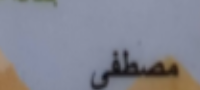

Name: مصطفى
Confidence: 0.9452112317085266


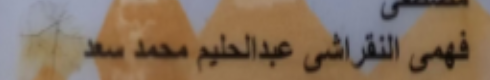

Name: فهمى النقراشى عدالحيم محمدس
Confidence: 0.7053360939025879


In [ ]:
img = read_image("/content/file95.png")
img_output=perspective_transform(img)
print(img_output.shape)

first_name_img=crop_first_name(img_output)
full_name_img=crop_full_name(img_output)


cv2_imshow(first_name_img)
print("="*50)
first_name, conf = field_paddle(first_name_img)
print("Name:", first_name)
print("Confidence:", conf)

cv2_imshow(full_name_img)
print("="*50)
full_name, conf = field_paddle(full_name_img)
print("Name:", full_name)
print("Confidence:", conf)



# Id Ocr

In [ ]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 629.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 6.2 MB/s eta 0:00:00


In [ ]:
def id_ocr(img, ocr_model, conf=0.3,imgsz=1280):
    # 1. Run inference directly on BGR image
    result = ocr_model.predict(source=img, conf=conf, verbose=False)[0]

    # 2. Sort bounding boxes strictly from Left to Right by x1
    sorted_boxes = sorted(result.boxes, key=lambda b: b.xyxy[0][0].item())

    detected_numbers = []
    annotated_img = img.copy()

    # 3. Process each detected digit
    for box in sorted_boxes:
        cls_id = int(box.cls[0].item())
        label = result.names[cls_id]

        if label.isdigit():
            detected_numbers.append(label)

            # Get box coordinates
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)

            # Draw green bounding box
            cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (0, 255, 0), 2)

            # Draw label above the box
            cv2.putText(
                annotated_img,
                label,
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    # 4. Display the annotated image
    cv2_imshow(annotated_img)

    # 5. Join digits as standard English string
    return "".join(detected_numbers)

Plan A (Pass 1): Standard contrast detection successful.
(600, 750, 3)


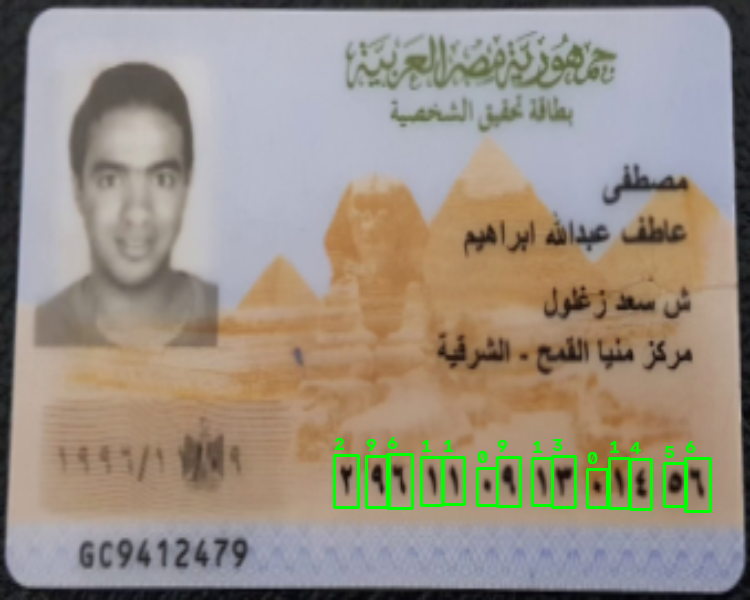

id: 29611091301456


In [ ]:
from ultralytics import YOLO

ocr_model = YOLO("/content/best.pt")  # OCR model

img = read_image("/content/file48.png")
img_output=perspective_transform(img)
print(img_output.shape)

# first_name_img=crop_first_name(img_output)
# full_name_img=crop_full_name(img_output)
id_img=crop_id(img_output)


# cv2_imshow(img_output)
print("="*50)
id = id_ocr(img_output,ocr_model,conf=.3)
print("id:", id)


In [ ]:
def decode_egyptian_id(id_number):
    governorates = {
        '01': 'Cairo',
        '02': 'Alexandria',
        '03': 'Port Said',
        '04': 'Suez',
        '11': 'Damietta',
        '12': 'Dakahlia',
        '13': 'EL-Sharqia',
        '14': 'Kaliobeya',
        '15': 'Kafr El-Sheikh',
        '16': 'Gharbia',
        '17': 'Monoufia',
        '18': 'El-Beheira',
        '19': 'Ismailia',
        '21': 'Giza',
        '22': 'Beni Suef',
        '23': 'Fayoum',
        '24': 'El-Menia',
        '25': 'Assiut',
        '26': 'Sohag',
        '27': 'Qena',
        '28': 'Aswan',
        '29': 'Luxor',
        '31': 'Red Sea',
        '32': 'New Valley',
        '33': 'Matrouh',
        '34': 'North Sinai',
        '35': 'South Sinai',
        '88': 'Foreign'
    }

    if not id_number :
        return "id is empty"

    if len(id_number)!=14:
        return "invalid id"

    century_digit = int(id_number[0])
    year = int(id_number[1:3])
    month = int(id_number[3:5])
    day = int(id_number[5:7])
    governorate_code = id_number[7:9]
    gender_code = int(id_number[12:13])

    if century_digit == 2:
        century = "1900-1999"
        full_year = 1900 + year
    elif century_digit == 3:
        century = "2000-2099"
        full_year = 2000 + year
    else:
        raise ValueError("Invalid century digit")

    gender = "Male" if gender_code % 2 != 0 else "Female"
    governorate = governorates.get(governorate_code, "Unknown")
    birth_date = f"{full_year:04d}-{month:02d}-{day:02d}"

    return {
        "year":year,
        "month":month,
        "day":day,
        'Birth Date': birth_date,
        'Governorate': governorate,
        'Gender': gender
    }

Plan A (Pass 1): Standard contrast detection successful.
(600, 750, 3)


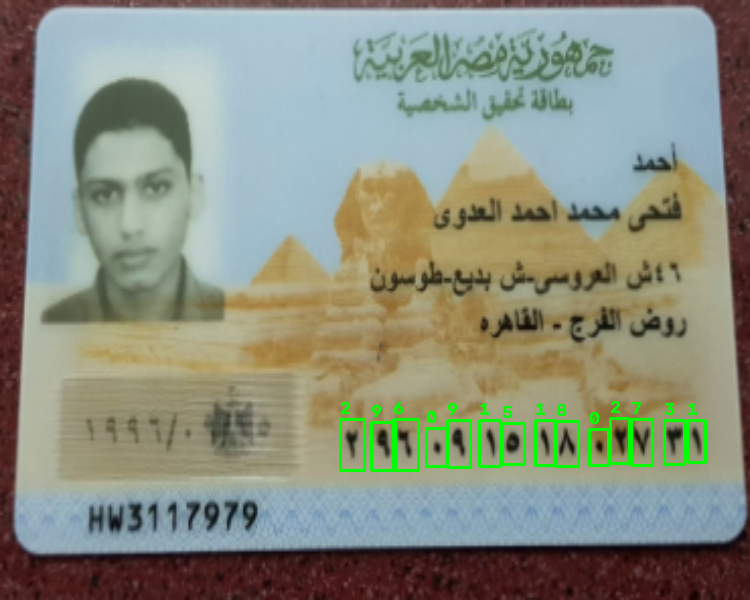

id: 29609151802731
year 96
month 9
day 15
Birth Date 1996-09-15
Governorate El-Beheira
Gender Male


In [ ]:
from ultralytics import YOLO

ocr_model = YOLO("/content/best.pt")  # OCR model

img = read_image("/content/file36.png")
img_output=perspective_transform(img)
print(img_output.shape)

id_img=crop_id(img_output)


print("="*50)
id = id_ocr(img_output,ocr_model,conf=.3)
id_info=decode_egyptian_id(id)
if id_info=="id is empty" or id_info=="invalid id":
  print(id_info)
else:
  print("id:", id)
  print(f"year {id_info['year']}")
  print(f"month {id_info['month']}")
  print(f"day {id_info['day']}")
  print(f"Birth Date {id_info['Birth Date']}")
  print(f"Governorate {id_info['Governorate']}")
  print(f"Gender {id_info['Gender']}")



# FULL PIPELINE

Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/arabic_PP-OCRv5_mobile_rec`.


Plan A (Pass 1): Standard contrast detection successful.
(600, 750, 3)


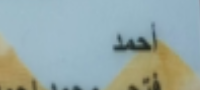

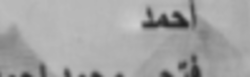

Name: أحمد سا
Confidence: 0.7092195153236389


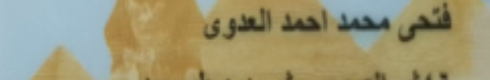

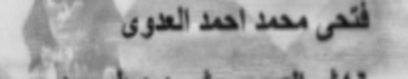

Name: فتحى محمداحمد العدوى
Confidence: 0.8195542097091675


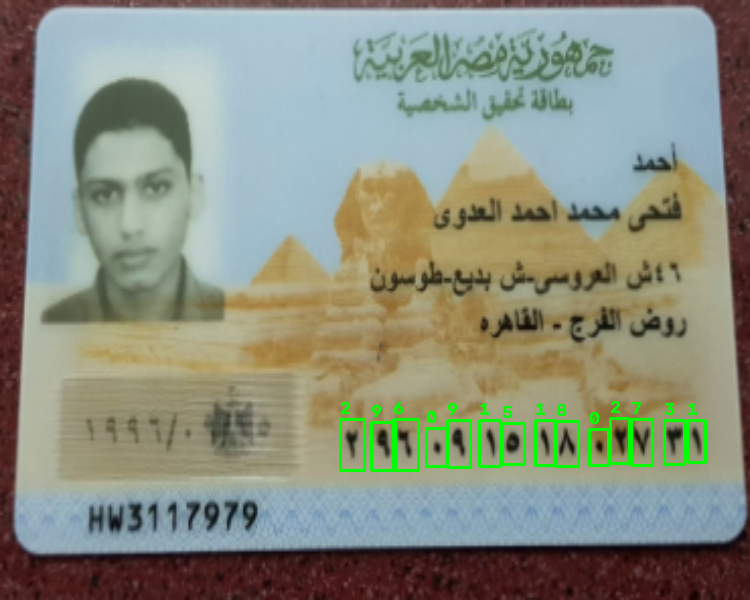

id: 29609151802731
year 96
month 9
day 15
Birth Date 1996-09-15
Governorate El-Beheira
Gender Male


In [ ]:
from paddleocr import PaddleOCR
from ultralytics import YOLO
from paddleocr import TextRecognition

rec_model = TextRecognition(
    model_name="arabic_PP-OCRv5_mobile_rec",
    device="cpu",
    enable_mkldnn=False
)
ocr_model = YOLO("/content/best.pt")

img = read_image("/content/file36.png")
img_output=perspective_transform(img)
print(img_output.shape)

first_name_img=crop_first_name(img_output)
full_name_img=crop_full_name(img_output)
id_img=crop_id(img_output)

# First Name
cv2_imshow(first_name_img)
print("="*50)
first_name, conf = field_paddle(first_name_img)
print("Name:", first_name)
print("Confidence:", conf)

#Full Name
cv2_imshow(full_name_img)
print("="*50)
full_name, conf = field_paddle(full_name_img)
print("Name:", full_name)
print("Confidence:", conf)

# Id Number Info
id = id_ocr(img_output,ocr_model,conf=.3)
id_info=decode_egyptian_id(id)
if id_info=="id is empty" or id_info=="invalid id":
  print(id_info)
else:
  print("id:", id)
  print(f"year {id_info['year']}")
  print(f"month {id_info['month']}")
  print(f"day {id_info['day']}")
  print(f"Birth Date {id_info['Birth Date']}")
  print(f"Governorate {id_info['Governorate']}")
  print(f"Gender {id_info['Gender']}")



In [ ]:
def extract_id_data(image_path, ocr_model, show_images=False):
    """
    Processes an Egyptian ID card image to extract first name, full name, and ID details.

    Parameters:
    - image_path (str or numpy.ndarray): Path to the image file or the image array.
    - ocr_model: The loaded YOLO model for ID detection.
    - show_images (bool): Whether to display the cropped field images using cv2_imshow.

    Returns:
    - dict: A dictionary containing first name, full name, and decoded ID information.
    """
    # 1. Read and transform image
    img = read_image(image_path) if isinstance(image_path, str) else image_path
    img_output = perspective_transform(img)

    # 2. Crop specific regions
    first_name_img = crop_first_name(img_output)
    full_name_img = crop_full_name(img_output)

    # Optional display
    if show_images:
        print("--- First Name Image ---")
        cv2_imshow(first_name_img)
        print("="*50)
        print("--- Full Name Image ---")
        cv2_imshow(full_name_img)
        print("="*50)

    # 3. Extract text for names
    first_name, fn_conf = field_paddle(first_name_img)
    full_name, ln_conf = field_paddle(full_name_img)

    # 4. Extract and decode ID number
    id_number = id_ocr(img_output, ocr_model, conf=0.3)
    id_info = decode_egyptian_id(id_number)

    # Handle invalid or empty ID cases safely inside the dictionary structure
    if id_info in ["id is empty", "invalid id"]:
        formatted_id_info = {"status": id_info}
    else:
        formatted_id_info = id_info

    # 5. Compile results into a structured dictionary
    result = {
        "first_name": first_name,
        "first_name_confidence": fn_conf,
        "full_name": full_name,
        "full_name_confidence": ln_conf,
        "id_number": id_number if id_info not in ["id is empty", "invalid id"] else None,
        "id_info": formatted_id_info
    }

    return result

Plan A (Pass 1): Standard contrast detection successful.


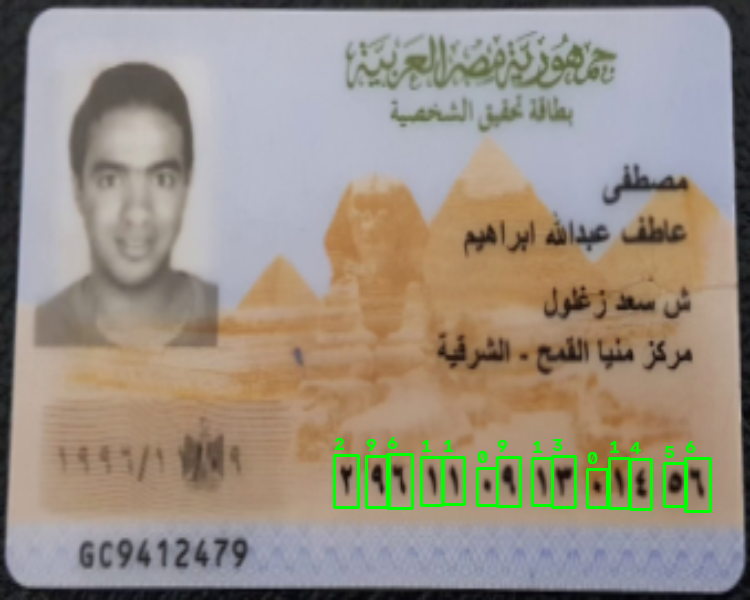

Extracted Results Summary:
{'first_name': 'مصطفى', 'first_name_confidence': 0.9308063387870789, 'full_name': 'عاطف عبالفه براهيم', 'full_name_confidence': 0.7936750054359436, 'id_number': '29611091301456', 'id_info': {'year': 96, 'month': 11, 'day': 9, 'Birth Date': '1996-11-09', 'Governorate': 'EL-Sharqia', 'Gender': 'Male'}}
Name: مصطفى عاطف عبالفه براهيم
ID Number: 29611091301456
Birth Date: 1996-11-09
Governorate: EL-Sharqia


In [ ]:
# Call the function once your models are initialized
extracted_data = extract_id_data("/content/file48.png", ocr_model)

# Access the returned dictionary
print("Extracted Results Summary:")
print(extracted_data)

# Example of accessing specific fields:
print(f"Name: {extracted_data['first_name']} {extracted_data['full_name']}")
print(f"ID Number: {extracted_data['id_number']}")
if isinstance(extracted_data['id_info'], dict):
    print(f"Birth Date: {extracted_data['id_info'].get('Birth Date')}")
    print(f"Governorate: {extracted_data['id_info'].get('Governorate')}")
else:
    print(extracted_data['id_info'])

# save this notbook in drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp "/content/drive/MyDrive/Colab Notebooks/ID Verfication.ipynb" "/content/drive/MyDrive/ID Scan/Notebooks/"